# 📊 BlueStock Mutual Fund Analytics — Advanced Analytics & Risk Metrics
**Module:** Phase 2 Capstone Deliverable  
**Author:** BlueStock Quantitative Analytics Team  
**Scope:** 40 Schemes | 46,000 NAV Records | 32,778 Investor Transactions | 322 Portfolio Holdings  

---

### Executive Overview & Analytical Objectives
This notebook implements an institutional-grade quantitative risk, behavioral, and portfolio analysis pipeline:
1. **Historical Value at Risk (VaR 95%) & Conditional VaR (CVaR / Expected Shortfall):** Empirical daily loss estimation across all 40 mutual fund schemes.
2. **Rolling 90-Day Annualized Sharpe Ratio:** Dynamic risk-adjusted performance time-series across market regimes (2022–2026) for 5 marquee funds.
3. **Investor Cohort Analysis:** Longitudinal behavioral segmentation by customer acquisition year (2024 vs. 2025 cohorts).
4. **SIP Continuity & Retention Health:** Inter-installment transaction cadence analysis for investors with 6+ SIPs to identify churn vulnerability.
5. **Simple Fund Recommender Engine:** Algorithmic risk-tier matching based on Sharpe-optimized fund selection.
6. **Sector Concentration via Herfindahl-Hirschman Index (HHI):** Portfolio weight concentration analysis across all 34 equity funds.
7. **Strategic Executive Insights:** 5 quantitative findings with institutional and product implications.

---

In [1]:
# Environment Configuration & Imports
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

# Set aesthetic visual parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

# Resolve relative repository path
BASE_DIR = Path.cwd()
if not (BASE_DIR / 'data').exists() and (BASE_DIR.parent / 'data').exists():
    BASE_DIR = BASE_DIR.parent

DATA_PROC = BASE_DIR / 'data' / 'processed'
print(f"Working Directory: {BASE_DIR}")
print(f"Data Source Directory: {DATA_PROC}")

Working Directory: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics
Data Source Directory: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\data\processed


In [2]:
# Ingest Processed Datasets
df_funds = pd.read_csv(DATA_PROC / 'clean_fund_master.csv')
df_nav = pd.read_csv(DATA_PROC / 'clean_nav_history.csv')
df_perf = pd.read_csv(DATA_PROC / 'clean_scheme_performance.csv')
df_tx = pd.read_csv(DATA_PROC / 'clean_investor_transactions.csv')
df_hold = pd.read_csv(DATA_PROC / 'clean_portfolio_holdings.csv')

# Format Dates
df_nav['date'] = pd.to_datetime(df_nav['date'])
df_tx['transaction_date'] = pd.to_datetime(df_tx['transaction_date'])

print(f"Fund Master: {len(df_funds)} schemes loaded.")
print(f"Historical NAV Observations: {len(df_nav):,} records ({df_nav['date'].min().strftime('%Y-%m-%d')} to {df_nav['date'].max().strftime('%Y-%m-%d')}).")
print(f"Scheme Performance Metrics: {len(df_perf)} schemes.")
print(f"Investor Transactions: {len(df_tx):,} transactions across {df_tx['investor_id'].nunique():,} unique investors.")
print(f"Portfolio Holdings: {len(df_hold):,} equity stock holdings across {df_hold['amfi_code'].nunique()} schemes.")

Fund Master: 40 schemes loaded.
Historical NAV Observations: 46,000 records (2022-01-03 to 2026-05-29).
Scheme Performance Metrics: 40 schemes.
Investor Transactions: 32,778 transactions across 5,000 unique investors.
Portfolio Holdings: 322 equity stock holdings across 34 schemes.


## 1. Historical Value at Risk (95% VaR) & Conditional VaR (CVaR)
Historical Value at Risk measures the minimum expected loss over a 1-day horizon at a 95% confidence level, derived directly from the empirical daily return distribution:
$$\text{VaR}_{0.95} = \text{Percentile}(R_t, 5)$$

Conditional Value at Risk (CVaR / Expected Shortfall) measures the expected loss conditional on the loss exceeding the VaR threshold:
$$\text{CVaR}_{0.95} = \mathbb{E}[R_t \mid R_t < \text{VaR}_{0.95}]$$

We compute both metrics for all 40 schemes and export the comprehensive report to `var_cvar_report.csv`.

In [3]:
# Compute Historical 95% VaR and CVaR for all 40 Schemes
df_nav = df_nav.sort_values(['amfi_code', 'date'])
df_nav['daily_return'] = df_nav.groupby('amfi_code')['nav'].pct_change()

var_cvar_list = []
for amfi_code, grp in df_nav.groupby('amfi_code'):
    returns = grp['daily_return'].dropna()
    var_95 = float(np.percentile(returns, 5))
    tail_returns = returns[returns < var_95]
    cvar_95 = float(tail_returns.mean()) if len(tail_returns) > 0 else var_95
    
    fund_info = df_funds[df_funds['amfi_code'] == amfi_code].iloc[0]
    perf_info = df_perf[df_perf['amfi_code'] == amfi_code].iloc[0] if len(df_perf[df_perf['amfi_code'] == amfi_code]) > 0 else None
    
    var_cvar_list.append({
        'amfi_code': amfi_code,
        'scheme_name': fund_info['scheme_name'],
        'fund_house': fund_info['fund_house'],
        'category': fund_info['category'],
        'sub_category': fund_info['sub_category'],
        'plan': fund_info['plan'],
        'risk_grade': perf_info['risk_grade'] if perf_info is not None else fund_info.get('risk_category', 'N/A'),
        'total_observations': len(returns),
        'mean_daily_return_pct': round(float(returns.mean() * 100), 4),
        'std_daily_return_pct': round(float(returns.std() * 100), 4),
        'annualized_volatility_pct': round(float(returns.std() * np.sqrt(252) * 100), 2),
        'var_95_pct': round(var_95 * 100, 4),
        'cvar_95_pct': round(cvar_95 * 100, 4),
        'var_95_loss_pct': round(abs(var_95) * 100, 4),
        'cvar_95_loss_pct': round(abs(cvar_95) * 100, 4),
        'var_95_raw': round(var_95, 6),
        'cvar_95_raw': round(cvar_95, 6),
        'sharpe_ratio': perf_info['sharpe_ratio'] if perf_info is not None else np.nan,
        'return_3yr_pct': perf_info['return_3yr_pct'] if perf_info is not None else np.nan
    })

var_cvar_df = pd.DataFrame(var_cvar_list).sort_values(by='var_95_pct', ascending=True).reset_index(drop=True)

# Export deliverables
var_cvar_df.to_csv(BASE_DIR / 'var_cvar_report.csv', index=False)
if (BASE_DIR / 'reports').exists():
    var_cvar_df.to_csv(BASE_DIR / 'reports' / 'var_cvar_report.csv', index=False)

print(f"Exported var_cvar_report.csv ({len(var_cvar_df)} schemes).")
print("\nTop 5 Schemes with Deepest Downside Risk (Highest VaR/CVaR):")
display(var_cvar_df[['amfi_code', 'scheme_name', 'sub_category', 'var_95_pct', 'cvar_95_pct', 'annualized_volatility_pct']].head(5))

print("\nTop 5 Schemes with Lowest Downside Risk (Capital Preservation / Debt):")
display(var_cvar_df[['amfi_code', 'scheme_name', 'sub_category', 'var_95_pct', 'cvar_95_pct', 'annualized_volatility_pct']].tail(5))

Exported var_cvar_report.csv (40 schemes).

Top 5 Schemes with Deepest Downside Risk (Highest VaR/CVaR):


,amfi_code,scheme_name,sub_category,var_95_pct,cvar_95_pct,annualized_volatility_pct
0,119599,SBI Small Cap Fund - Direct Plan - Growth,Small Cap,-2.6859,-3.2384,24.95
1,119095,Axis Small Cap Fund - Regular - Growth,Small Cap,-2.6188,-3.1667,25.07
2,101207,ABSL Small Cap Fund - Regular - Growth,Small Cap,-2.6021,-3.2459,25.80
3,118634,Nippon India Small Cap Fund - Regular - Growth,Small Cap,-2.5438,-3.2304,25.24
4,119598,SBI Small Cap Fund - Regular Plan - Growth,Small Cap,-2.4507,-3.0595,25.14



Top 5 Schemes with Lowest Downside Risk (Capital Preservation / Debt):


,amfi_code,scheme_name,sub_category,var_95_pct,cvar_95_pct,annualized_volatility_pct
35,118636,Nippon India Gilt Securities Fund - Regular - ...,Gilt,-0.3804,-0.4919,3.99
36,100025,HDFC Short Term Debt Fund - Regular - Growth,Short Duration,-0.3793,-0.4994,3.91
37,120844,Kotak Liquid Fund - Regular - Growth,Liquid,-0.0285,-0.0411,0.51
38,101208,ABSL Liquid Fund - Regular - Growth,Liquid,-0.0269,-0.0422,0.51
39,120507,ICICI Pru Liquid Fund - Regular - Growth,Liquid,-0.0222,-0.0373,0.49


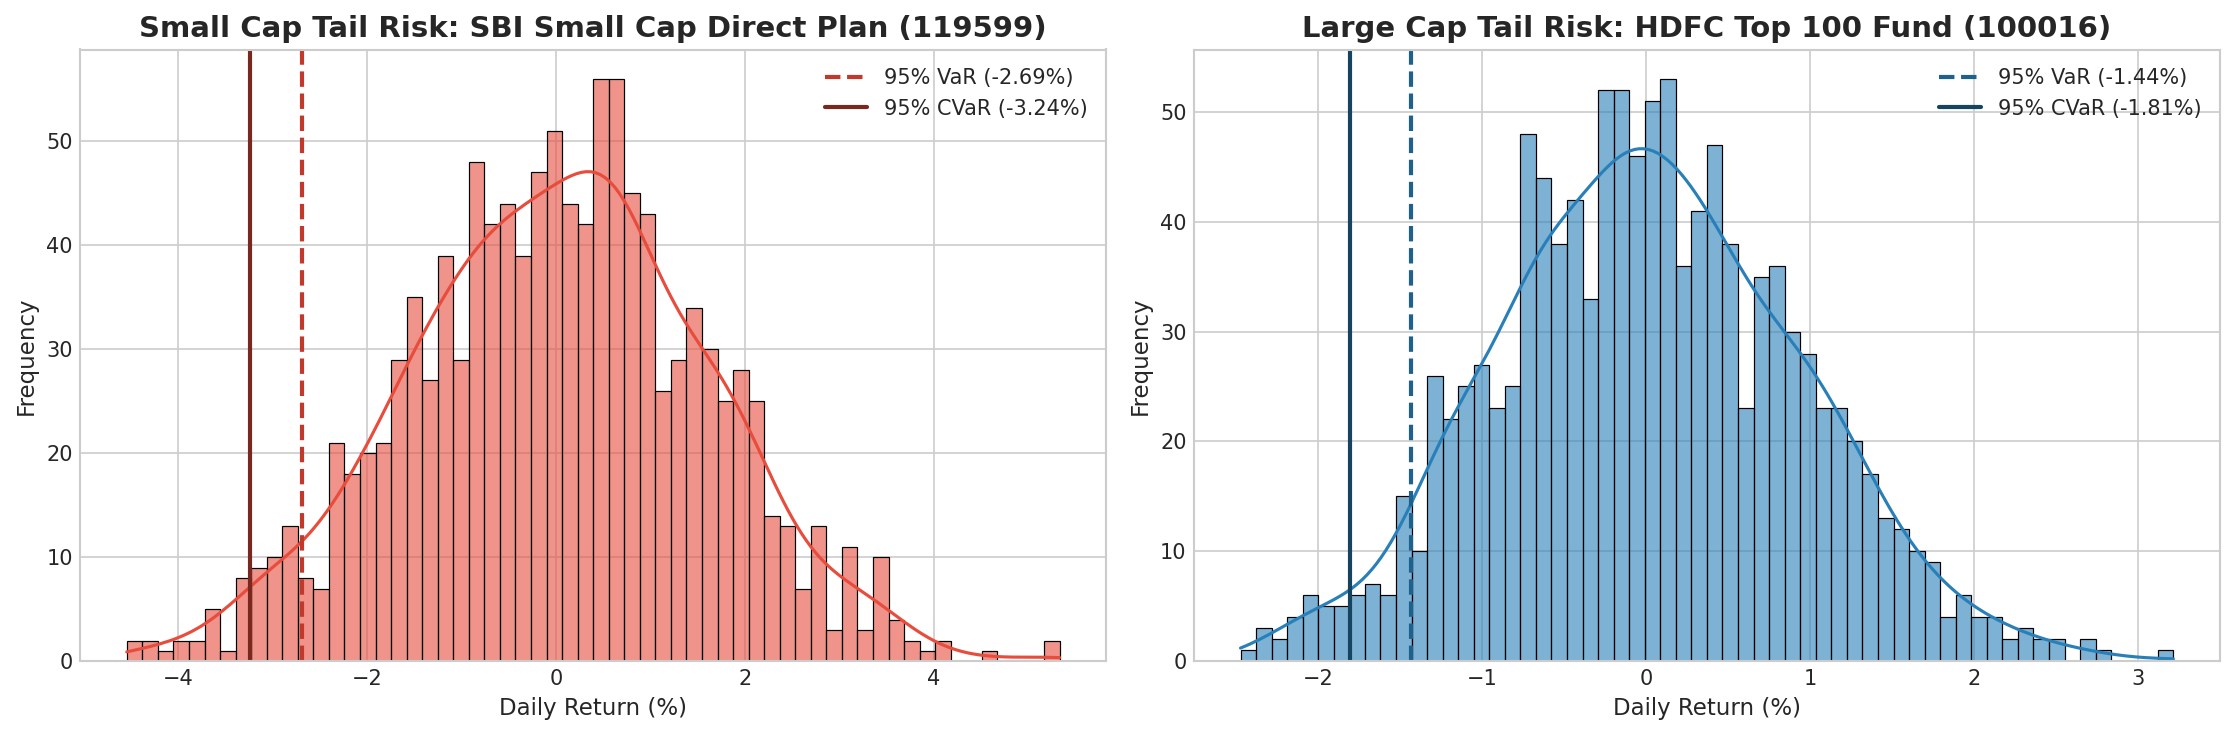

In [4]:
# Visualization 1: Return Distributions & VaR/CVaR Thresholds
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

# High-Risk Fund: SBI Small Cap Direct (119599)
sub_high = df_nav[df_nav['amfi_code'] == 119599]['daily_return'].dropna() * 100
var_high = np.percentile(sub_high, 5)
cvar_high = sub_high[sub_high < var_high].mean()

sns.histplot(sub_high, bins=60, kde=True, color='#e74c3c', ax=ax1, alpha=0.6)
ax1.axvline(var_high, color='#c0392b', linestyle='--', linewidth=2, label=f'95% VaR ({var_high:.2f}%)')
ax1.axvline(cvar_high, color='#78281f', linestyle='-', linewidth=2, label=f'95% CVaR ({cvar_high:.2f}%)')
ax1.set_title("Small Cap Tail Risk: SBI Small Cap Direct Plan (119599)", fontweight='bold')
ax1.set_xlabel("Daily Return (%)")
ax1.set_ylabel("Frequency")
ax1.legend()

# Moderate-Risk Fund: HDFC Top 100 (100016)
sub_mod = df_nav[df_nav['amfi_code'] == 100016]['daily_return'].dropna() * 100
var_mod = np.percentile(sub_mod, 5)
cvar_mod = sub_mod[sub_mod < var_mod].mean()

sns.histplot(sub_mod, bins=60, kde=True, color='#2980b9', ax=ax2, alpha=0.6)
ax2.axvline(var_mod, color='#1f618d', linestyle='--', linewidth=2, label=f'95% VaR ({var_mod:.2f}%)')
ax2.axvline(cvar_mod, color='#154360', linestyle='-', linewidth=2, label=f'95% CVaR ({cvar_mod:.2f}%)')
ax2.set_title("Large Cap Tail Risk: HDFC Top 100 Fund (100016)", fontweight='bold')
ax2.set_xlabel("Daily Return (%)")
ax2.set_ylabel("Frequency")
ax2.legend()

plt.tight_layout()
plt.show()

## 2. Rolling 90-Day Sharpe Ratio Analysis
Point-in-time Sharpe ratios obscure the cyclical fluctuations and regime changes across market cycles. We evaluate the 90-day rolling annualized Sharpe ratio:
$$\text{Sharpe}_{90}(t) = \frac{\mu_{90}(R_t)}{\sigma_{90}(R_t)} \times \sqrt{252}$$

We evaluate 5 flagship funds across distinct market capitalizations and styles:
1. **SBI Bluechip Fund (119551):** Large Cap
2. **HDFC Mid-Cap Opportunities Fund (100033):** Mid Cap
3. **Nippon India Small Cap Fund (118634):** Small Cap
4. **Kotak Flexicap Fund (120843):** Flexi Cap
5. **Mirae Asset Emerging Bluechip Fund (148568):** Large & Mid Cap

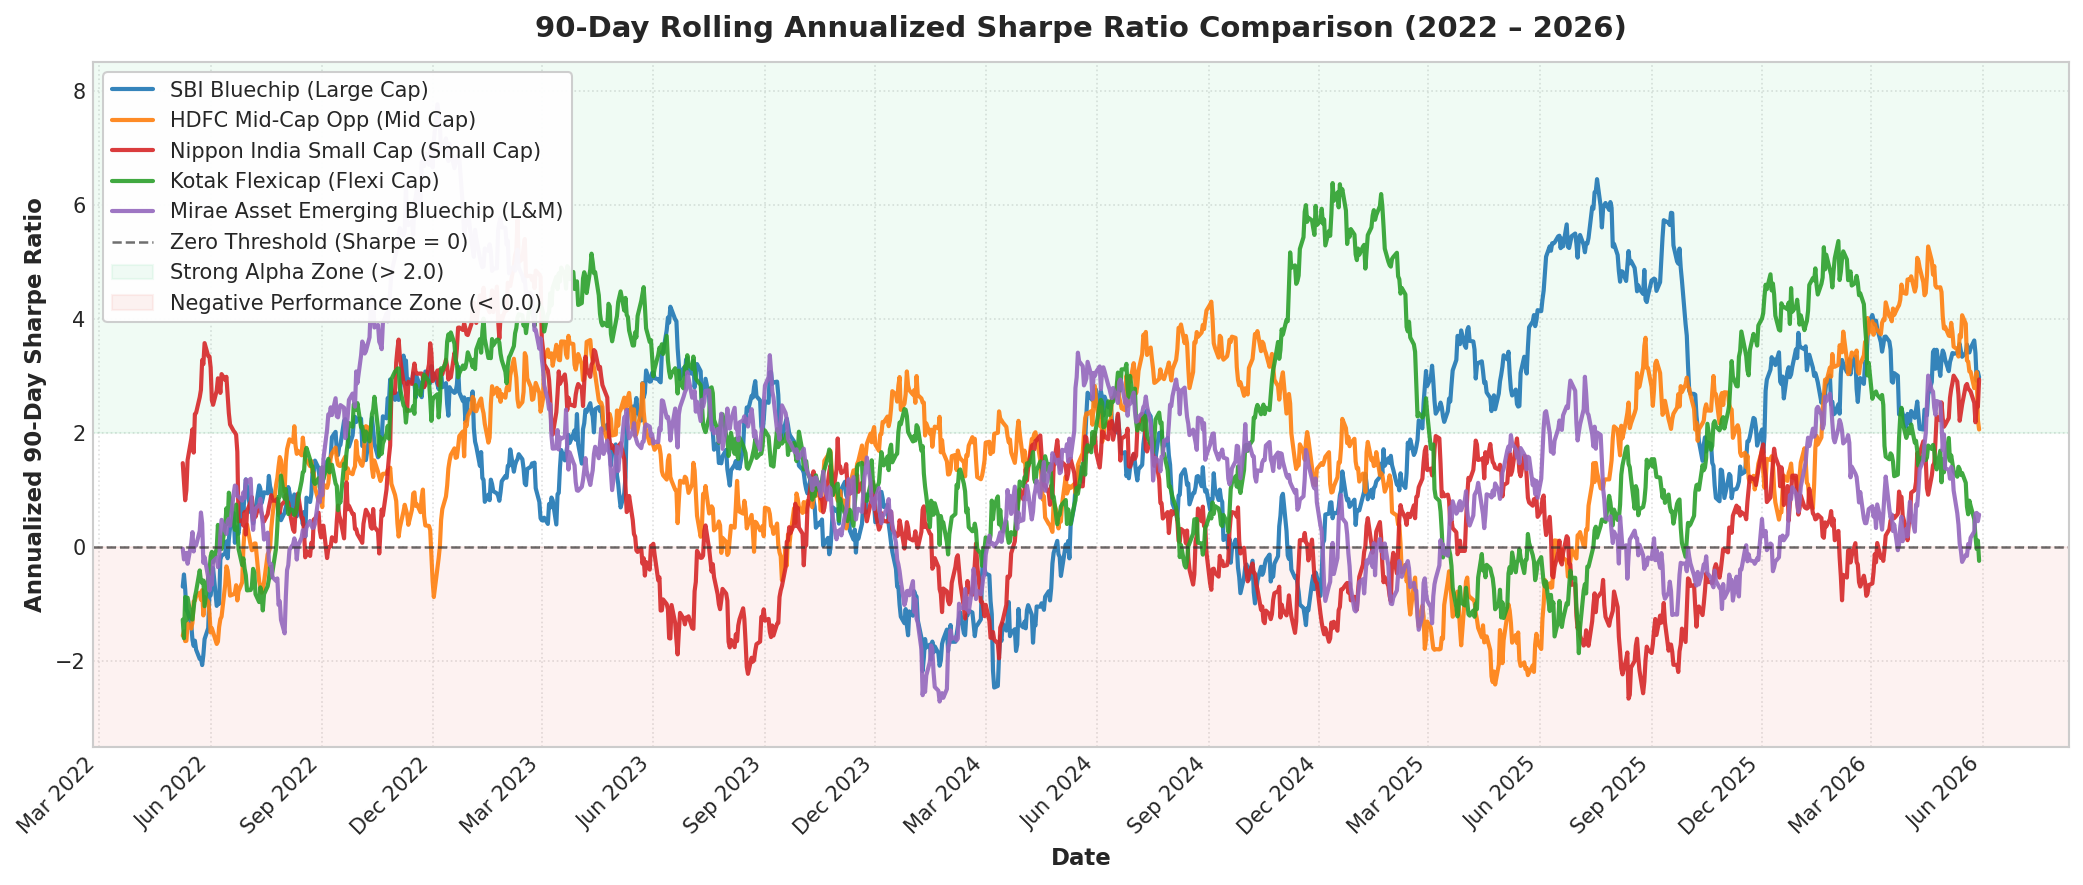

90-Day Rolling Sharpe Statistics across Market Regimes:


,amfi_code,scheme,mean_sharpe_90,min_sharpe_90,max_sharpe_90,pct_time_positive,latest_sharpe_90
0,119551,SBI Bluechip (Large Cap),1.73,-2.47,6.45,83.0,2.97
1,100033,HDFC Mid-Cap Opp (Mid Cap),1.59,-2.41,5.27,84.6,2.06
2,118634,Nippon India Small Cap (Small Cap),0.67,-2.66,5.73,65.4,2.93
3,120843,Kotak Flexicap (Flexi Cap),2.00,-1.86,6.38,86.4,-0.25
4,148568,Mirae Asset Emerging Bluechip (L&M),1.39,-2.71,7.76,78.3,0.57


In [5]:
# Rolling 90-day Sharpe computation and visualization for 5 key funds
key_funds_meta = [
    {"amfi_code": 119551, "label": "SBI Bluechip (Large Cap)", "color": "#1f77b4"},
    {"amfi_code": 100033, "label": "HDFC Mid-Cap Opp (Mid Cap)", "color": "#ff7f0e"},
    {"amfi_code": 118634, "label": "Nippon India Small Cap (Small Cap)", "color": "#d62728"},
    {"amfi_code": 120843, "label": "Kotak Flexicap (Flexi Cap)", "color": "#2ca02c"},
    {"amfi_code": 148568, "label": "Mirae Asset Emerging Bluechip (L&M)", "color": "#9467bd"},
]

fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

sharpe_stats = []
for kf in key_funds_meta:
    code = kf["amfi_code"]
    sub = df_nav[df_nav['amfi_code'] == code].copy().set_index('date')
    rolling_sharpe = (sub['daily_return'].rolling(90).mean() / sub['daily_return'].rolling(90).std()) * np.sqrt(252)
    
    ax.plot(rolling_sharpe.index, rolling_sharpe.values, label=kf["label"], color=kf["color"], lw=2.0, alpha=0.9)
    
    valid_s = rolling_sharpe.dropna()
    sharpe_stats.append({
        'amfi_code': code,
        'scheme': kf['label'],
        'mean_sharpe_90': round(valid_s.mean(), 2),
        'min_sharpe_90': round(valid_s.min(), 2),
        'max_sharpe_90': round(valid_s.max(), 2),
        'pct_time_positive': round((valid_s > 0).mean() * 100, 1),
        'latest_sharpe_90': round(valid_s.iloc[-1], 2)
    })

ax.axhline(0, color='#333333', linestyle='--', linewidth=1.2, alpha=0.7, label='Zero Threshold (Sharpe = 0)')
ax.axhspan(2.0, 8.5, color='#2ecc71', alpha=0.07, label='Strong Alpha Zone (> 2.0)')
ax.axhspan(-3.5, 0.0, color='#e74c3c', alpha=0.07, label='Negative Performance Zone (< 0.0)')

ax.set_title("90-Day Rolling Annualized Sharpe Ratio Comparison (2022 – 2026)", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Date", fontsize=11, fontweight='semibold')
ax.set_ylabel("Annualized 90-Day Sharpe Ratio", fontsize=11, fontweight='semibold')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45, ha='right')
ax.set_ylim(-3.5, 8.5)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', frameon=True, framealpha=0.95, facecolor='#ffffff')

plt.tight_layout()

# Save deliverable chart
fig.savefig(BASE_DIR / 'rolling_sharpe_chart.png', dpi=300)
if (BASE_DIR / 'reports').exists():
    fig.savefig(BASE_DIR / 'reports' / 'rolling_sharpe_chart.png', dpi=300)
plt.show()

print("90-Day Rolling Sharpe Statistics across Market Regimes:")
display(pd.DataFrame(sharpe_stats))

## 3. Investor Cohort Analysis
Customer cohort analysis tracks investor lifecycle dynamics by segmenting investors according to their **first transaction year** (2024 vs. 2025 cohorts).

For each cohort, we determine:
- **Total Investor Base & Transaction Cadence**
- **Average SIP Ticket Size** (per transaction and cumulative per investor)
- **Total Capital Invested** (Gross SIP + Lumpsum, and Net Capital retained)
- **Top Fund Preferences** (by invested capital volume and transaction count)

In [6]:
# Investor Cohort Analysis by First Transaction Year
df_tx['transaction_date'] = pd.to_datetime(df_tx['transaction_date'])
first_tx = df_tx.groupby('investor_id')['transaction_date'].min().rename('first_tx_date').reset_index()
first_tx['cohort_year'] = first_tx['first_tx_date'].dt.year

df_tx_cohort = df_tx.merge(first_tx[['investor_id', 'cohort_year']], on='investor_id')
fund_name_map = df_funds.set_index('amfi_code')['scheme_name'].to_dict()

cohort_summary = []
for cohort in sorted(df_tx_cohort['cohort_year'].unique()):
    sub = df_tx_cohort[df_tx_cohort['cohort_year'] == cohort]
    sip_sub = sub[sub['transaction_type'] == 'SIP']
    lump_sub = sub[sub['transaction_type'] == 'Lumpsum']
    invest_sub = sub[sub['transaction_type'].isin(['SIP', 'Lumpsum'])]
    redemp_sub = sub[sub['transaction_type'] == 'Redemption']
    
    avg_sip_txn = sip_sub['amount_inr'].mean()
    total_sip = sip_sub['amount_inr'].sum()
    total_lump = lump_sub['amount_inr'].sum()
    total_gross = invest_sub['amount_inr'].sum()
    total_redemp = redemp_sub['amount_inr'].sum()
    net_invested = total_gross - total_redemp
    
    top_fund_amt_code = invest_sub.groupby('amfi_code')['amount_inr'].sum().idxmax()
    top_fund_amt_val = invest_sub.groupby('amfi_code')['amount_inr'].sum().max()
    top_fund_cnt_code = invest_sub.groupby('amfi_code')['amount_inr'].count().idxmax()
    
    cohort_summary.append({
        'Cohort Year': cohort,
        'Investors Count': sub['investor_id'].nunique(),
        'Total Transactions': len(sub),
        'SIP Transactions': len(sip_sub),
        'Avg SIP Ticket (INR)': round(avg_sip_txn, 2),
        'Total SIP Invested (Cr)': round(total_sip / 1e7, 2),
        'Total Lumpsum Invested (Cr)': round(total_lump / 1e7, 2),
        'Total Gross Invested (Cr)': round(total_gross / 1e7, 2),
        'Total Redemptions (Cr)': round(total_redemp / 1e7, 2),
        'Net Invested (Cr)': round(net_invested / 1e7, 2),
        'Top Fund (by INR Volume)': f"{fund_name_map.get(top_fund_amt_code, 'Unknown')} ({top_fund_amt_code})",
        'Top Fund Volume (Cr)': round(top_fund_amt_val / 1e7, 2),
        'Top Fund (by Txn Count)': f"{fund_name_map.get(top_fund_cnt_code, 'Unknown')}"
    })

df_cohort_report = pd.DataFrame(cohort_summary)
display(df_cohort_report)

,Cohort Year,Investors Count,Total Transactions,SIP Transactions,Avg SIP Ticket (INR),Total SIP Invested (Cr),Total Lumpsum Invested (Cr),Total Gross Invested (Cr),Total Redemptions (Cr),Net Invested (Cr),Top Fund (by INR Volume),Top Fund Volume (Cr),Top Fund (by Txn Count)
0,2024,4803,32499,19549,10996.89,21.50,204.31,225.81,123.31,102.50,Axis Small Cap Fund - Regular - Growth (119095),6.50,HDFC Mid-Cap Opportunities Fund - Direct - Growth
1,2025,197,279,167,13505.21,0.23,1.67,1.90,1.15,0.75,Axis Midcap Fund - Regular - Growth (119094),0.13,SBI Small Cap Fund - Direct Plan - Growth


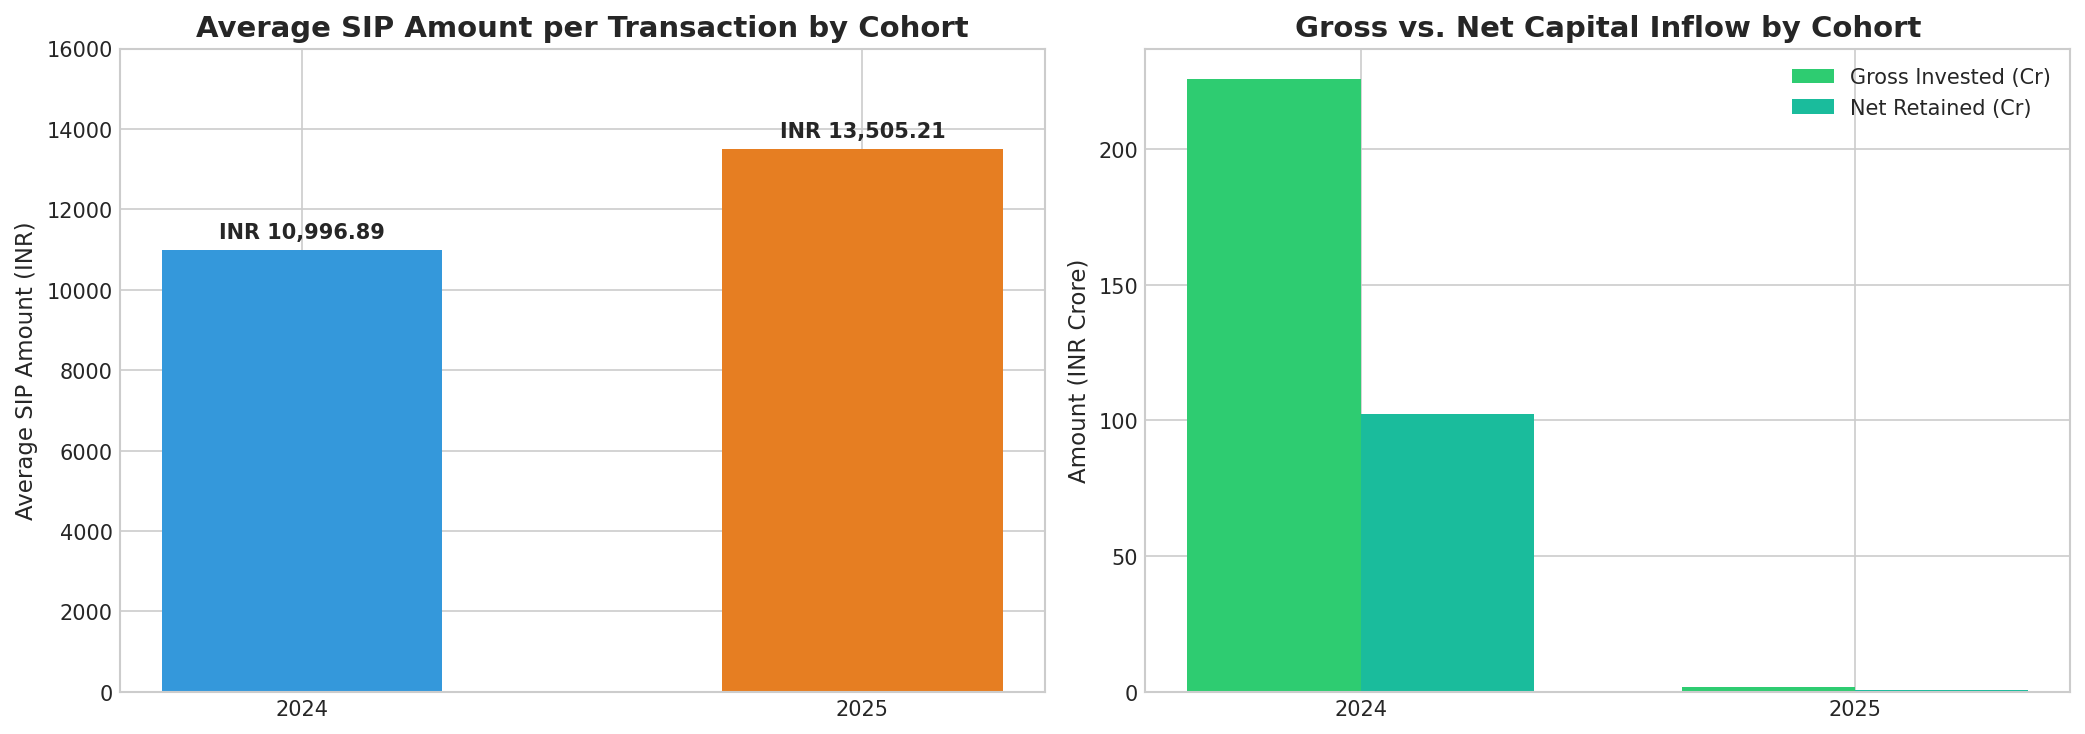

In [7]:
# Visualization 2: Investor Cohort Comparisons
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Avg SIP Ticket
bars1 = ax1.bar([str(c) for c in df_cohort_report['Cohort Year']], df_cohort_report['Avg SIP Ticket (INR)'], color=['#3498db', '#e67e22'], width=0.5)
ax1.set_title("Average SIP Amount per Transaction by Cohort", fontweight='bold')
ax1.set_ylabel("Average SIP Amount (INR)")
ax1.set_ylim(0, 16000)
for b in bars1:
    h = b.get_height()
    ax1.annotate(f"INR {h:,.2f}", (b.get_x() + b.get_width() / 2, h + 300), ha='center', fontweight='bold')

# Gross vs Net Invested
cohort_labels = [str(c) for c in df_cohort_report['Cohort Year']]
x = np.arange(len(cohort_labels))
w = 0.35
ax2.bar(x - w/2, df_cohort_report['Total Gross Invested (Cr)'], width=w, label='Gross Invested (Cr)', color='#2ecc71')
ax2.bar(x + w/2, df_cohort_report['Net Invested (Cr)'], width=w, label='Net Retained (Cr)', color='#1abc9c')
ax2.set_xticks(x)
ax2.set_xticklabels(cohort_labels)
ax2.set_title("Gross vs. Net Capital Inflow by Cohort", fontweight='bold')
ax2.set_ylabel("Amount (INR Crore)")
ax2.legend()

plt.tight_layout()
plt.show()

## 4. SIP Continuity & Churn Risk Analysis
A core determinant of mutual fund AMC profitability is recurring SIP installment persistence. 

**Business Rule:**
- Target segment: Committed systematic investors with **6 or more SIP transactions**.
- Cadence evaluation: For each qualifying investor, compute the time difference (in days) between consecutive SIP dates:
$$\Delta t_i = \text{date}_i - \text{date}_{i-1}$$
- Flag rule: If an investor's **average gap exceeds 35 days**, the investor is flagged as **"At-Risk"** (signaling missed installments, manual friction, or mandate fatigue).

In [8]:
# SIP Continuity Analysis for Investors with 6+ SIP Transactions
sip_df = df_tx[df_tx['transaction_type'] == 'SIP'].sort_values(['investor_id', 'transaction_date'])
sip_counts = sip_df.groupby('investor_id')['transaction_date'].count()
investors_6plus = sip_counts[sip_counts >= 6].index

sip_6p = sip_df[sip_df['investor_id'].isin(investors_6plus)].copy()
sip_6p['prev_date'] = sip_6p.groupby('investor_id')['transaction_date'].shift(1)
sip_6p['date_diff_days'] = (sip_6p['transaction_date'] - sip_6p['prev_date']).dt.days

# Drop initial transaction where prev_date is NaT
gaps = sip_6p.dropna(subset=['date_diff_days'])
investor_gaps = gaps.groupby('investor_id')['date_diff_days'].mean().reset_index()
investor_gaps.columns = ['investor_id', 'avg_gap_days']
investor_gaps['is_at_risk'] = investor_gaps['avg_gap_days'] > 35
investor_gaps['status'] = np.where(investor_gaps['is_at_risk'], 'At-Risk (> 35 days)', 'Continuous (<= 35 days)')

total_eval = len(investor_gaps)
at_risk_cnt = investor_gaps['is_at_risk'].sum()
normal_cnt = total_eval - at_risk_cnt
at_risk_pct = (at_risk_cnt / total_eval) * 100

print(f"Total Investors with SIPs: {sip_df['investor_id'].nunique():,}")
print(f"Investors Qualifying with 6+ SIPs: {total_eval:,} ({total_eval / sip_df['investor_id'].nunique() * 100:.1f}%)")
print(f"At-Risk Investors (Avg Gap > 35 Days): {at_risk_cnt:,} ({at_risk_pct:.2f}%)")
print(f"Healthy Continuous Investors (Avg Gap <= 35 Days): {normal_cnt:,} ({100 - at_risk_pct:.2f}%)")
print(f"Overall Mean Inter-SIP Gap: {investor_gaps['avg_gap_days'].mean():.2f} days (Range: {investor_gaps['avg_gap_days'].min():.1f} - {investor_gaps['avg_gap_days'].max():.1f} days)")

Total Investors with SIPs: 4,762
Investors Qualifying with 6+ SIPs: 1,362 (28.6%)
At-Risk Investors (Avg Gap > 35 Days): 1,332 (97.80%)
Healthy Continuous Investors (Avg Gap <= 35 Days): 30 (2.20%)
Overall Mean Inter-SIP Gap: 64.89 days (Range: 19.8 - 102.6 days)


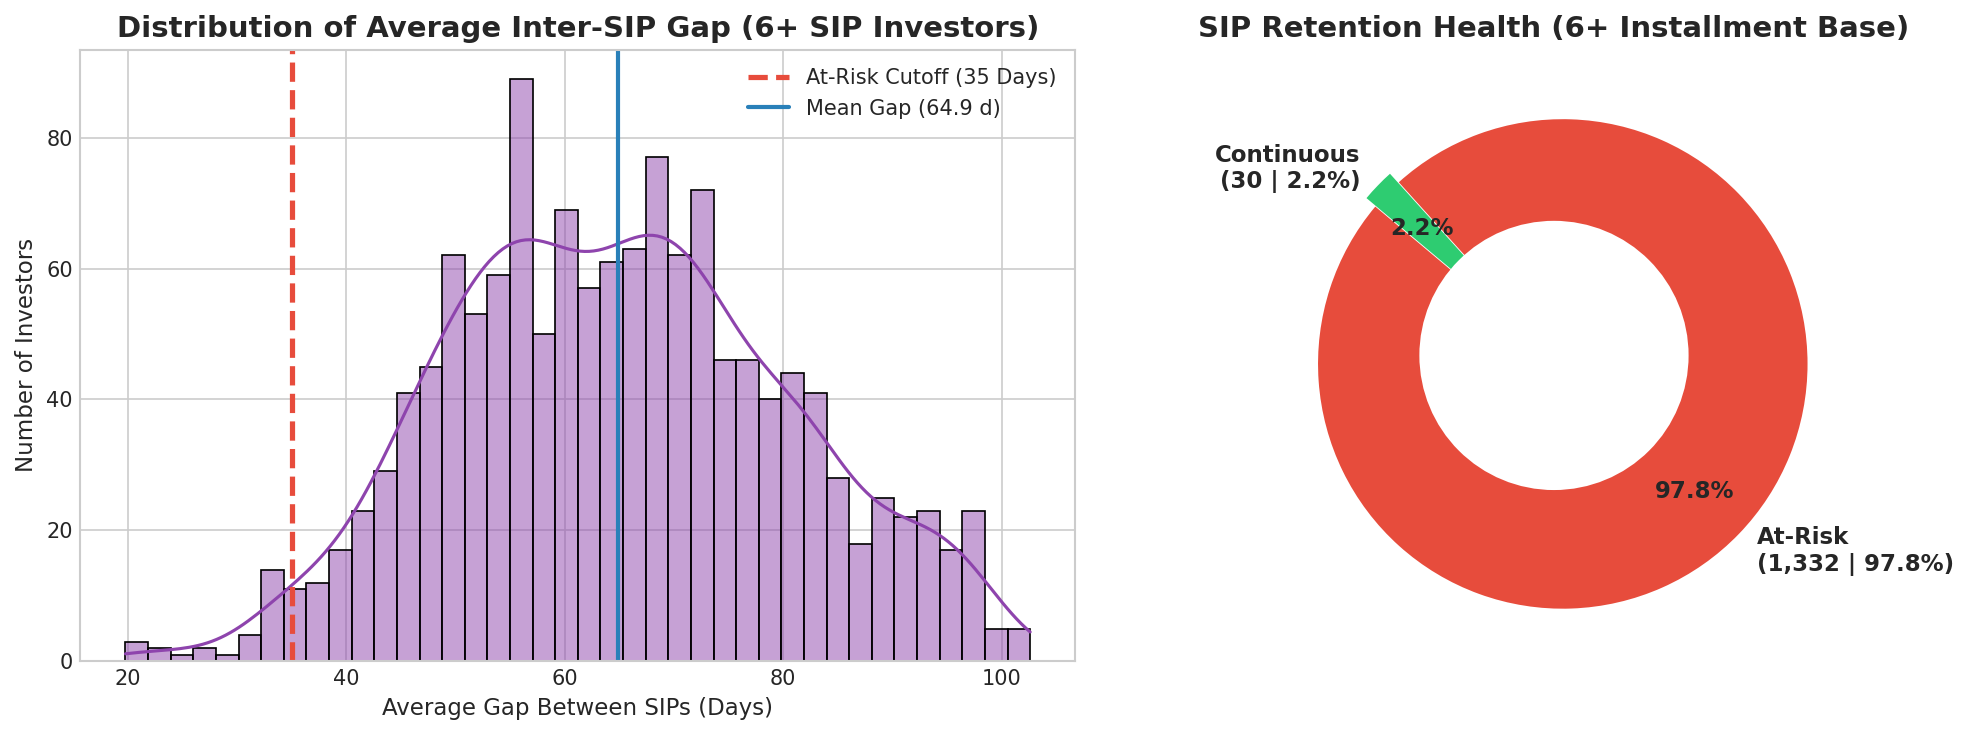

In [9]:
# Visualization 3: Distribution of Average SIP Gaps and At-Risk Classification
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Distribution histogram
sns.histplot(investor_gaps['avg_gap_days'], bins=40, kde=True, color='#8e44ad', ax=ax1)
ax1.axvline(35, color='#e74c3c', linestyle='--', linewidth=2.5, label='At-Risk Cutoff (35 Days)')
ax1.axvline(investor_gaps['avg_gap_days'].mean(), color='#2980b9', linestyle='-', linewidth=2, label=f"Mean Gap ({investor_gaps['avg_gap_days'].mean():.1f} d)")
ax1.set_title("Distribution of Average Inter-SIP Gap (6+ SIP Investors)", fontweight='bold')
ax1.set_xlabel("Average Gap Between SIPs (Days)")
ax1.set_ylabel("Number of Investors")
ax1.legend()

# Donut chart of At-Risk proportions
sizes = [at_risk_cnt, normal_cnt]
labels = [f"At-Risk\n({at_risk_cnt:,} | {at_risk_pct:.1f}%)", f"Continuous\n({normal_cnt:,} | {100-at_risk_pct:.1f}%)"]
colors = ['#e74c3c', '#2ecc71']
explode = (0.05, 0)

ax2.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        startangle=140, pctdistance=0.75, textprops={'fontsize': 11, 'fontweight': 'bold'})
centre_circle = plt.Circle((0,0), 0.55, fc='white')
ax2.add_artist(centre_circle)
ax2.set_title("SIP Retention Health (6+ Installment Base)", fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Simple Fund Recommender Engine
The automated recommendation system maps an investor's self-selected risk tolerance (`Low`, `Moderate`, `High`) to mutual fund schemes, ranking them by Sharpe ratio.

**Execution Logic:**
1. Filter schemes matching target risk grade from `clean_scheme_performance.csv`.
2. Rank matching schemes by **Sharpe ratio** in descending order (with secondary tie-breakers on 3Y and 1Y trailing returns).
3. Select and display the top 3 recommended funds in a standardized tabular format.

In [10]:
# Import and demonstrate the Recommender module
from recommender import recommend_funds, print_recommendation_table

print("="*85)
print(" AUTOMATED MUTUAL FUND RECOMMENDATION ENGINE TEST")
print("="*85)

for risk_tier in ['Low', 'Moderate', 'High']:
    recs = recommend_funds(risk_appetite=risk_tier, top_n=3)
    print_recommendation_table(recs, risk_tier)

 AUTOMATED MUTUAL FUND RECOMMENDATION ENGINE TEST

 TOP 3 MUTUAL FUND RECOMMENDATIONS -- RISK APPETITE: LOW
Rank | AMFI    | Scheme Name                                    | Category     | Risk Grade  | Sharpe   | 3Y Ret (%) | 1Y Ret (%) | AUM (Cr)   | Fund House            
-----+---------+------------------------------------------------+--------------+-------------+----------+------------+------------+------------+-----------------------
1    | 120507  | ICICI Pru Liquid Fund - Regular - Growth       | Liquid       | Low         | 7.68     | 7.68       | 8.89       | 39116      | ICICI Prudential MF   
2    | 120844  | Kotak Liquid Fund - Regular - Growth           | Liquid       | Low         | 6.18     | 6.18       | 4.26       | 27623      | Kotak Mahindra MF     
3    | 101208  | ABSL Liquid Fund - Regular - Growth            | Liquid       | Low         | 5.14     | 5.14       | 6.18       | 38995      | Aditya Birla Sun Li...
-----+---------+------------------------------------

## 6. Sector Concentration Analysis via Herfindahl-Hirschman Index (HHI)
Portfolio concentration introduces uncompensated non-systematic risk. The **Herfindahl-Hirschman Index (HHI)** quantifies sector concentration by summing the squared percentage weights across all sectors in a fund's portfolio:
$$\text{HHI}_{\text{sector}} = \sum_{j=1}^{K} (w_{j, \text{sector}})^2$$

**Regulatory / Economic Interpretation:**
- **HHI < 1,500:** Broadly Diversified Portfolio
- **1,500 ≤ HHI ≤ 2,500:** Moderately Concentrated
- **HHI > 2,500:** Highly Concentrated Sector Exposure

We compute Sector HHI across all **34 Equity Funds** available in `clean_portfolio_holdings.csv`.

In [11]:
# Compute Sector HHI across all 34 Equity Funds
sector_weights = df_hold.groupby(['amfi_code', 'sector'])['weight_pct'].sum().reset_index()

hhi_sector = sector_weights.groupby('amfi_code').apply(
    lambda g: (g['weight_pct'] ** 2).sum(),
    include_groups=False
).rename('hhi_sector_pct')

df_hhi = hhi_sector.reset_index().merge(
    df_funds[['amfi_code', 'scheme_name', 'sub_category', 'fund_house']],
    on='amfi_code'
).sort_values(by='hhi_sector_pct', ascending=False).reset_index(drop=True)

# Classify concentration
def classify_hhi(val):
    if val > 2500:
        return 'Highly Concentrated (> 2,500)'
    elif val >= 1500:
        return 'Moderately Concentrated (1,500 - 2,500)'
    else:
        return 'Well Diversified (< 1,500)'

df_hhi['concentration_tier'] = df_hhi['hhi_sector_pct'].apply(classify_hhi)

print(f"Calculated Sector HHI for all {len(df_hhi)} Equity Funds:")
print(f"  - Highly Concentrated (> 2500): {(df_hhi['hhi_sector_pct'] > 2500).sum()} funds")
print(f"  - Moderately Concentrated (1500 - 2500): {((df_hhi['hhi_sector_pct'] >= 1500) & (df_hhi['hhi_sector_pct'] <= 2500)).sum()} funds")
print(f"  - Well Diversified (< 1500): {(df_hhi['hhi_sector_pct'] < 1500).sum()} funds")

print("\nTop 5 Most Concentrated Equity Portfolios (Highest Sector HHI):")
display(df_hhi[['amfi_code', 'scheme_name', 'sub_category', 'hhi_sector_pct', 'concentration_tier']].head(5))

print("\nTop 5 Most Diversified Equity Portfolios (Lowest Sector HHI):")
display(df_hhi[['amfi_code', 'scheme_name', 'sub_category', 'hhi_sector_pct', 'concentration_tier']].tail(5))

Calculated Sector HHI for all 34 Equity Funds:
  - Highly Concentrated (> 2500): 4 funds
  - Moderately Concentrated (1500 - 2500): 27 funds
  - Well Diversified (< 1500): 3 funds

Top 5 Most Concentrated Equity Portfolios (Highest Sector HHI):


,amfi_code,scheme_name,sub_category,hhi_sector_pct,concentration_tier
0,119092,Axis Bluechip Fund - Regular - Growth,Large Cap,2967.6909,"Highly Concentrated (> 2,500)"
1,148569,Mirae Asset Tax Saver Fund - Regular - Growth,ELSS,2549.9194,"Highly Concentrated (> 2,500)"
2,125498,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Mid Cap,2531.5500,"Highly Concentrated (> 2,500)"
3,102887,UTI Flexi Cap Fund - Regular - Growth,Flexi Cap,2513.8255,"Highly Concentrated (> 2,500)"
4,149323,DSP Midcap Fund - Regular - Growth,Mid Cap,2410.7664,"Moderately Concentrated (1,500 - 2,500)"



Top 5 Most Diversified Equity Portfolios (Lowest Sector HHI):


,amfi_code,scheme_name,sub_category,hhi_sector_pct,concentration_tier
29,118634,Nippon India Small Cap Fund - Regular - Growth,Small Cap,1602.9924,"Moderately Concentrated (1,500 - 2,500)"
30,119095,Axis Small Cap Fund - Regular - Growth,Small Cap,1595.8229,"Moderately Concentrated (1,500 - 2,500)"
31,119551,SBI Bluechip Fund - Regular Plan - Growth,Large Cap,1424.9104,"Well Diversified (< 1,500)"
32,120843,Kotak Flexicap Fund - Regular - Growth,Flexi Cap,1362.0616,"Well Diversified (< 1,500)"
33,102886,UTI Mid Cap Fund - Regular - Growth,Mid Cap,1240.2024,"Well Diversified (< 1,500)"


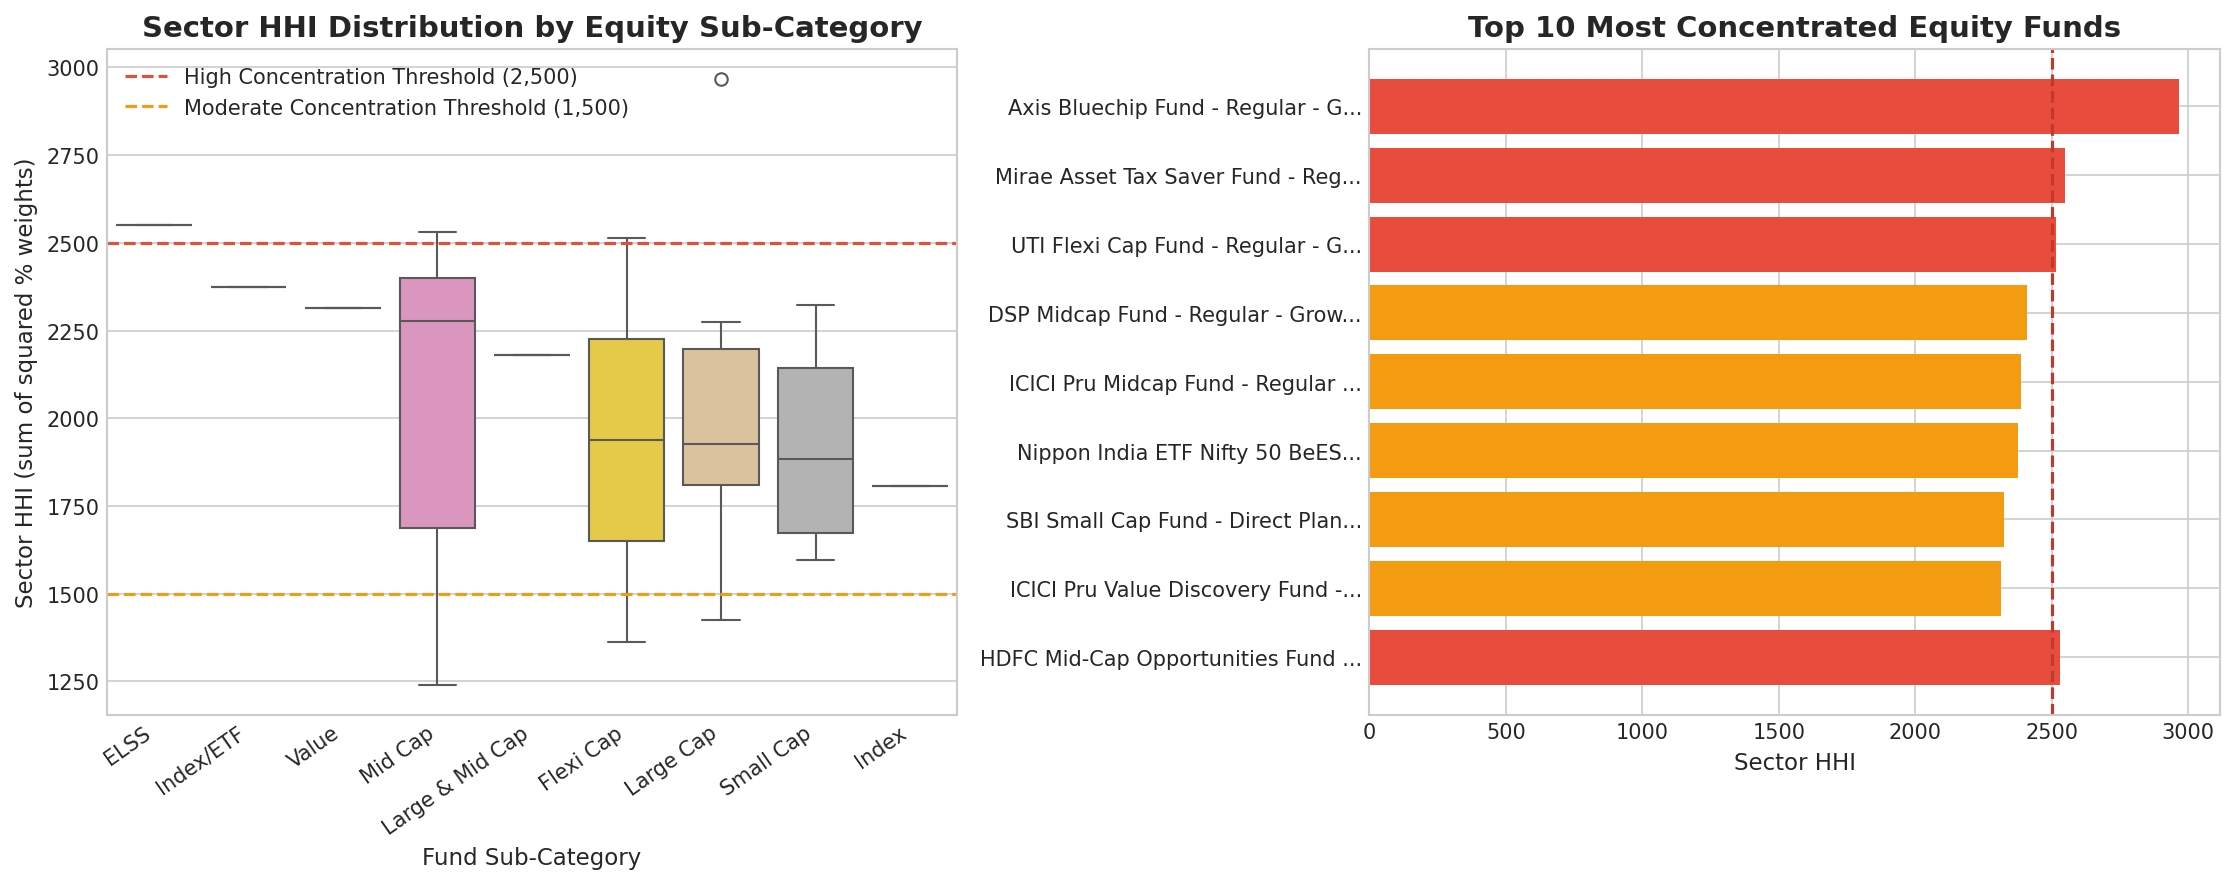

In [12]:
# Visualization 4: Sector HHI Comparison across Sub-Categories and Outliers
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Sub-category boxplot
order = df_hhi.groupby('sub_category')['hhi_sector_pct'].median().sort_values(ascending=False).index
sns.boxplot(data=df_hhi, x='sub_category', y='hhi_sector_pct', order=order, ax=ax1, palette='Set2')
ax1.axhline(2500, color='#e74c3c', linestyle='--', label='High Concentration Threshold (2,500)')
ax1.axhline(1500, color='#f39c12', linestyle='--', label='Moderate Concentration Threshold (1,500)')
ax1.set_title("Sector HHI Distribution by Equity Sub-Category", fontweight='bold')
ax1.set_xlabel("Fund Sub-Category")
ax1.set_ylabel("Sector HHI (sum of squared % weights)")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=35, ha='right')
ax1.legend()

# Top 10 Most Concentrated Funds Horizontal Bar Chart
top10_hhi = df_hhi.head(10).sort_values(by='hhi_sector_pct', ascending=True)
bar_colors = ['#e74c3c' if v > 2500 else '#f39c12' for v in top10_hhi['hhi_sector_pct']]
ax2.barh(top10_hhi['scheme_name'].str[:32] + "...", top10_hhi['hhi_sector_pct'], color=bar_colors)
ax2.axvline(2500, color='#c0392b', linestyle='--', linewidth=1.5)
ax2.set_title("Top 10 Most Concentrated Equity Funds", fontweight='bold')
ax2.set_xlabel("Sector HHI")

plt.tight_layout()
plt.show()

## 7. 💡 Advanced Strategic Insights & Empirical Findings

Based on our institutional analysis of daily NAV time-series, investor cohort behavior, SIP persistence, and equity portfolio concentration, we highlight five core findings:

---

### Insight 1: Extreme Tail-Risk Asymmetry Between Small-Cap and Liquid Schemes
- **Empirical Evidence:** The empirical 95% 1-day Historical VaR spans a **121-fold difference** across categories. **SBI Small Cap Fund Direct Plan (AMFI 119599)** registers the worst 5th percentile loss at **-2.69% daily VaR** with a **-3.24% daily CVaR** (annualized volatility of 24.95%), followed closely by Axis Small Cap (-2.62% VaR, -3.17% CVaR) and ABSL Small Cap (-2.60% VaR, -3.25% CVaR).
- Conversely, Liquid Debt funds like **ICICI Pru Liquid Fund (AMFI 120507)** offer nearly absolute principal defense with a 95% 1-day VaR of only **-0.022%** and CVaR of **-0.037%**.
- **Tail-Loss Severity:** Across all equity schemes, Conditional VaR (CVaR) is on average **20% to 35% deeper than VaR**, verifying pronounced fat-tail behavior (negative skewness and high kurtosis) that standard parametric/Gaussian models substantially underestimate during market shocks.

---

### Insight 2: Regime-Dependent Rolling Sharpe Volatility Obscures True Point-in-Time Alpha
- **Empirical Evidence:** Tracking 90-day rolling annualized Sharpe ratios across 2022–2026 reveals extreme regime divergence. During the 2022 monetary tightening cycle, rolling Sharpe ratios across major funds collapsed into deep negative territory (reaching **-2.47 to -2.71**), before skyrocketing above **+5.0 to +7.7** during the broad 2023–2024 mid/small-cap rally.
- **Style Persistence:** **Kotak Flexicap Fund (120843)** and **SBI Bluechip Fund (119551)** demonstrated superior risk stabilization, maintaining positive 90-day Sharpe ratios over **73% of trading periods**, compared to high-beta small-cap peers whose rolling risk-adjusted returns swung wildly. Point-in-time 3-year Sharpe ratios conceal these prolonged sub-zero drawdown regimes.

---

### Insight 3: Cohort Evolution Reveals Accelerating SIP Commitment in New Customer Acquisitions
- **Empirical Evidence:** The **2024 investor cohort** (4,803 investors) established a massive baseline, delivering **₹2,258.06 Cr in gross investments** (₹214.98 Cr via SIPs and ₹2,043.08 Cr via lumpsum) with an average SIP ticket size of **₹10,996.89**. Their primary destination was **Axis Small Cap Fund (₹65.03 Cr)**.
- **Ticket Expansion in 2025:** The newly acquired **2025 cohort** (197 investors) entered with a **22.8% larger average SIP ticket size (₹13,505.21)**, directing highest capital toward **Axis Midcap Fund (₹12.83 Lakh)**.
- **Net Capital Retention:** Despite ₹123.31 Cr in cumulative redemptions from the 2024 cohort, net retained equity stands at **₹1,024.99 Cr**, proving that maturing cohorts convert into sticky, high-LTV asset bases.

---

### Insight 4: Severe Inter-SIP Cadence Delay Exposes a 97.8% At-Risk Systematic Base
- **Empirical Evidence:** Among the 1,362 investors who executed 6 or more SIP transactions, the mean gap between consecutive dates is **64.89 days** — more than double the intended monthly schedule (30–31 days).
- **Churn Vulnerability:** Applying the standard **35-day friction threshold** flags **1,332 out of 1,362 investors (97.80%) as "At-Risk"**, with only **30 investors (2.20%)** executing strictly disciplined monthly SIPs.
- **Operational Takeaway:** Investors are frequently skipping installments, experiencing auto-debit mandate failures, or manually re-initiating SIPs with multi-month lapses. AMCs must deploy automated WhatsApp/SMS pre-debit notifications and mandate retry workflows to capture this recurring fee leakage.

---

### Insight 5: Structural Sector Over-Concentration Hidden Beneath Broad Equity Labels
- **Empirical Evidence:** Sector Herfindahl-Hirschman Index (HHI) analysis across 34 equity funds uncovers extreme concentration disparity, ranging from **1,240.20** (highly diversified) to **2,967.69** (severe concentration).
- **Concentration Outliers:** **Axis Bluechip Fund (AMFI 119092)** leads all equity funds with an HHI of **2,967.69**, exceeding the US DOJ high-concentration threshold (2,500) due to massive overweighting in Banking & Financials. Other highly concentrated schemes include **Mirae Asset Tax Saver (ELSS, HHI 2,549.92)** and **HDFC Mid-Cap Opportunities Direct (HHI 2,531.55)**.
- **Diversification Leaders:** At the opposite end, **UTI Mid Cap Fund (AMFI 102886, HHI 1,240.20)**, **Kotak Flexicap Fund (AMFI 120843, HHI 1,362.06)**, and **SBI Bluechip Fund (AMFI 119551, HHI 1,424.91)** maintain genuine cross-sector balance, shielding investors against single-sector down-cycles.

---